# 03 - Model Evaluation
Evaluates the saved model against baselines using a held-out test set.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'Notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from backend import preprocessing as pp, model as tm

In [2]:
model, meta = tm.load_model()
pd.DataFrame(meta['metrics']).T

,mae,rmse,r2
xgboost,2.764504,4.444174,0.972299
baseline_last_hour,3.805633,5.720641,0.954100
baseline_same_hour_yesterday,5.910832,10.183435,0.854551
baseline_same_hour_last_week,4.329116,7.411897,0.922949


In [3]:
print('Best baseline:', meta['best_baseline'])
print('MAE improvement vs best baseline: %.1f%%' % meta['mae_improvement_vs_best_baseline_pct'])

Best baseline: baseline_last_hour
MAE improvement vs best baseline: 27.4%


## Actual vs Predicted (test set)

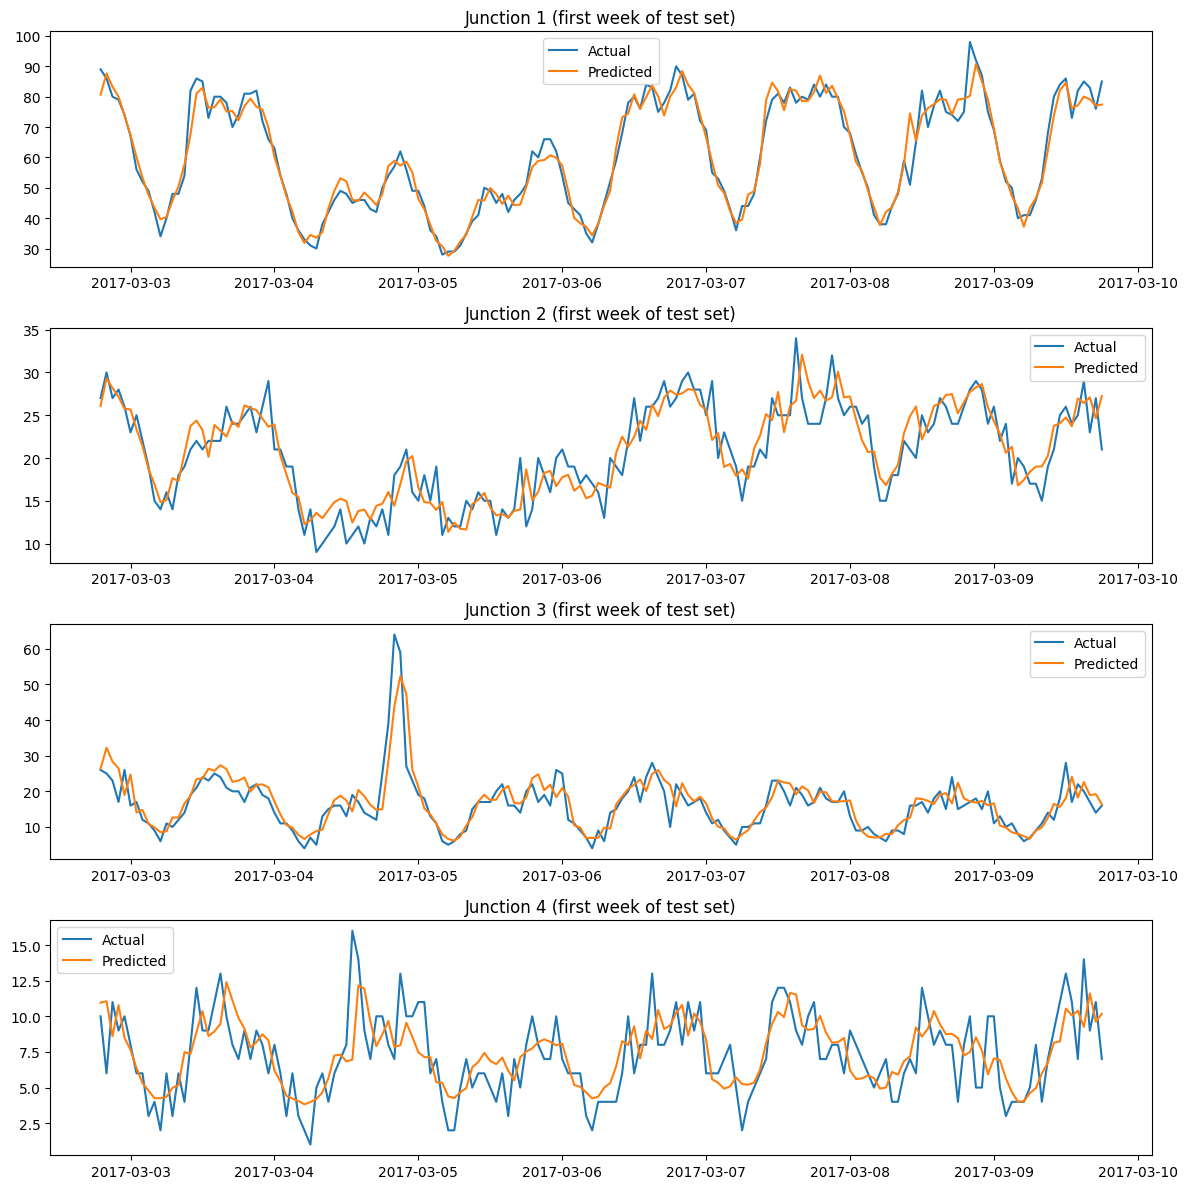

In [4]:
clean_df, _ = pp.clean(pp.load_raw())
features = pp.build_features(clean_df)
fig, axes = plt.subplots(4,1, figsize=(12,12), sharex=False)
for ax, j in zip(axes, sorted(features.Junction.unique())):
    ev = tm.evaluate_on_test_set(model, features, int(j)).head(24*7)
    ax.plot(ev.DateTime, ev.actual, label='Actual'); ax.plot(ev.DateTime, ev.predicted, label='Predicted')
    ax.set_title(f'Junction {j} (first week of test set)'); ax.legend()
plt.tight_layout(); plt.show()

## Residuals

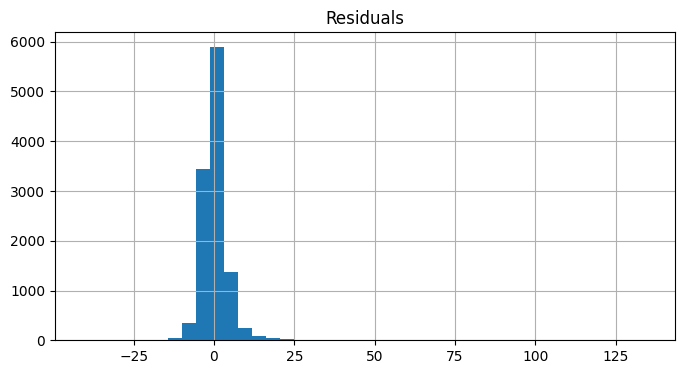

In [5]:
ev = pd.concat([tm.evaluate_on_test_set(model, features, int(j)) for j in features.Junction.unique()])
(ev.actual - ev.predicted).hist(bins=40, figsize=(8,4)); plt.title('Residuals'); plt.show()

## 24-hour forecast example

In [6]:
tm.forecast(model, clean_df, junction=1, horizon=24).head()

,DateTime,predicted
0,2017-07-01 00:00:00,72.467117
1,2017-07-01 01:00:00,61.411682
2,2017-07-01 02:00:00,53.716007
3,2017-07-01 03:00:00,46.554493
4,2017-07-01 04:00:00,39.649323
